# LAB 03
## Mô hình Linear Regression trên tập dữ liệu OpenFDA
- **Họ và tên:** Nguyễn Văn Phát
- **MSSV:** 24521314
- **Dataset:** openfda_drug_events.csv


## 1. Chuẩn bị dữ liệu
- biến mục tiêu target = Weight_kg (cân nặng bệnh nhân).
- features = ['Age', 'Sex', 'Num_Drugs', 'Hospitalization', 'Death', 'Disabling'].


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

df = pd.read_csv('openfda_drug_events.csv')

df = df[(df['Age'] > 0) & (df['Age'] <= 100) & (df['Weight_kg'] >= 10) & (df['Weight_kg'] <= 250)].copy()
df['Sex'] = df['Sex'].fillna(df['Sex'].mode()[0])

features = ['Age', 'Sex', 'Num_Drugs', 'Hospitalization', 'Death', 'Disabling']
target = 'Weight_kg'

X = df[features].values
y = df[target].values

# Chia tập train và test (tỷ lệ 8:2)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Kích thước tập train:", X_train.shape, y_train.shape)
print("Kích thước tập test:", X_test.shape, y_test.shape)


Kích thước tập train: (7855, 6) (7855,)
Kích thước tập test: (1964, 6) (1964,)



## 2. Assignment 1: Cài đặt Linear Regression bằng NumPy


In [3]:
class LinearRegressionNumPy:
    def __init__(self):
        self.w = None
        self.b = None

    def fit(self, X, y):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        theta = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y
        self.b = theta[0]
        self.w = theta[1:]

    def predict(self, X):
        return np.dot(X, self.w) + self.b

def evaluate(y_true, y_pred):
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_true - y_pred))
    r2 = 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)
    return mse, rmse, mae, r2


In [4]:
# Huan luyen mo hinh
model = LinearRegressionNumPy()
model.fit(X_train, y_train)

# Danh gia tren tapp test
y_pred = model.predict(X_test)
mse, rmse, mae, r2 = evaluate(y_test, y_pred)

print("Kết quả đánh giá")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")
print(f"R2:   {r2:.4f}")
print(f"Bias (b): {model.b:.4f}")
print("Weights (w):", np.round(model.w, 4))


Kết quả đánh giá
MSE:  467.8894
RMSE: 21.6308
MAE:  16.1692
R2:   0.0873
Bias (b): 82.6472
Weights (w): [ 0.1715 -9.575  -0.0352 -1.4987 -7.8605  2.1304]


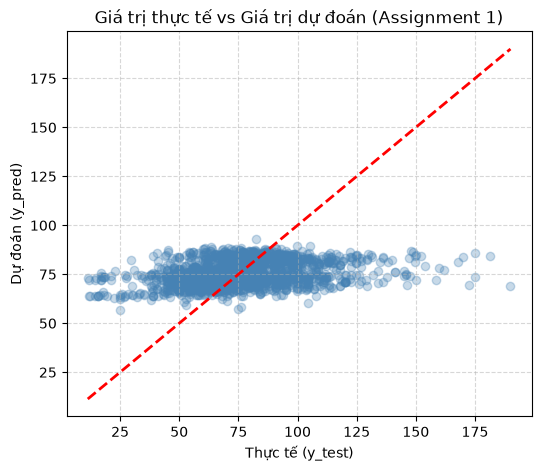

In [ ]:
# Truc quan gia thuc te va du doan
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.3, color='steelblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title("Giá trị thực tế vs Giá trị dự đoán (Assignment 1)")
plt.xlabel("Thực tế (y_test)")
plt.ylabel("Dự đoán (y_pred)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()



## 3. Assignment 2: Chuẩn hóa dữ liệu (Standardization)



In [ ]:
# Chuẩn hóa dữ liệu bằng Z-score
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)

X_train_std = (X_train - mean) / std
X_test_std = (X_test - mean) / std

# Huấn luyện
model_std = LinearRegressionNumPy()
model_std.fit(X_train_std, y_train)

# Danh gia mô hình chuẩn hóa
y_pred_std = model_std.predict(X_test_std)
mse_std, rmse_std, mae_std, r2_std = evaluate(y_test, y_pred_std)

# So sánh kết quả đánh giá
df_compare_ass2 = pd.DataFrame({
    'Độ đo': ['MSE', 'RMSE', 'MAE', 'R2'],
    'Dữ liệu gốc': [mse, rmse, mae, r2],
    'Dữ liệu chuẩn hóa': [mse_std, rmse_std, mae_std, r2_std]
})
print(df_compare_ass2.to_string(index=False))

# So sánh trọng số giữa 2 mô hình
df_weights = pd.DataFrame({
    'Feature': features,
    'Weight (Original)': np.round(model.w, 4),
    'Weight (Standardized)': np.round(model_std.w, 4)
})
print("\n--- So sánh trọng số giữa 2 mô hình ---")
print(df_weights.to_string(index=False))


Độ đo  Dữ liệu gốc  Dữ liệu chuẩn hóa
  MSE   467.889448         467.889448
 RMSE    21.630752          21.630752
  MAE    16.169232          16.169232
   R2     0.087292           0.087292

--- So sánh trọng số giữa 2 mô hình ---
        Feature  Weight (Original)  Weight (Standardized)
            Age             0.1715                 3.3977
            Sex            -9.5750                -4.7000
      Num_Drugs            -0.0352                -0.2179
Hospitalization            -1.4987                -0.7095
          Death            -7.8605                -2.0605
      Disabling             2.1304                 0.5185


**Nhận xét:**
- Sai số dự đoán (MSE, RMSE, MAE, R2) giữa hai mô hình hoàn toàn tương đương nhau do nghiệm đóng OLS không bị thay đổi bởi phép co giãn tuyến tính.
- Khi dữ liệu được chuẩn hóa về cùng phương sai bằng 1, các trọng số $\beta$ phản ánh trực tiếp mức độ quan trọng tương đối của từng biến: Sex và Age có hệ số tuyệt đối lớn nhất tác động đến Weight_kg.



## 4. Assignment 3: Kỹ nghệ đặc trưng xử lý đa cộng tuyến 



In [6]:
# Tạo thêm cột phụ thuộc tuyến tính
df_ass3 = df.copy()
df_ass3['Total_Adverse'] = df_ass3['Hospitalization'] + df_ass3['Death'] + df_ass3['Disabling']

cols_col = features + ['Total_Adverse']
X_col = df_ass3[cols_col].values
X_train_col, X_test_col = train_test_split(X_col, test_size=0.2, random_state=42)

# Kiểm tra hạng ma trận và chỉ số điều kiện (Condition Number)
X_b_col = np.c_[np.ones(len(X_train_col)), X_train_col]
rank_col = np.linalg.matrix_rank(X_b_col.T @ X_b_col)
cond_col = np.linalg.cond(X_b_col.T @ X_b_col)

# Huấn luyện mô hình khi có đa cộng tuyến
model_col = LinearRegressionNumPy()
model_col.fit(X_train_col, y_train)
y_pred_col = model_col.predict(X_test_col)
mse_col, rmse_col, mae_col, r2_col = evaluate(y_test, y_pred_col)

# Tiền xử lý: loại bỏ cột phụ thuộc tuyến tính
X_train_clean = X_train_col[:, :-1]
X_test_clean = X_test_col[:, :-1]
X_b_clean = np.c_[np.ones(len(X_train_clean)), X_train_clean]
rank_clean = np.linalg.matrix_rank(X_b_clean.T @ X_b_clean)
cond_clean = np.linalg.cond(X_b_clean.T @ X_b_clean)

model_clean = LinearRegressionNumPy()
model_clean.fit(X_train_clean, y_train)
y_pred_clean = model_clean.predict(X_test_clean)
mse_clean, rmse_clean, mae_clean, r2_clean = evaluate(y_test, y_pred_clean)

# So sánh trước và sau khi xử lý đa cộng tuyến
df_compare_ass3 = pd.DataFrame({
    'Thuộc tính': ['Số cột', 'Hạng ma trận (Rank)', 'Condition number', 'MSE', 'R2'],
    'Dữ liệu có đa cộng tuyến': [str(X_b_col.shape[1]), str(rank_col), f'{cond_col:.2e}', f'{mse_col:.4f}', f'{r2_col:.4f}'],
    'Dữ liệu đã xử lý': [str(X_b_clean.shape[1]), str(rank_clean), f'{cond_clean:.2e}', f'{mse_clean:.4f}', f'{r2_clean:.4f}']
})
print(df_compare_ass3.to_string(index=False))


         Thuộc tính Dữ liệu có đa cộng tuyến Dữ liệu đã xử lý
             Số cột                        8                7
Hạng ma trận (Rank)                        7                7
   Condition number                 2.54e+20         8.81e+04
                MSE                 467.8894         467.8894
                 R2                   0.0873           0.0873



## 5. Assignment 4: Cài đặt bằng Scikit-Learn và so sánh kết quả


In [7]:
from sklearn.linear_model import LinearRegression as SklearnLinearRegression

# Huấn luyện mô hình Scikit-Learn
sk_model = SklearnLinearRegression()
sk_model.fit(X_train, y_train)

# Đánh giá mô hình
y_pred_sk = sk_model.predict(X_test)
mse_sk, rmse_sk, mae_sk, r2_sk = evaluate(y_test, y_pred_sk)

# So sánh trọng số giữa NumPy và Scikit-Learn
diff_w = float(np.max(np.abs(model.w - sk_model.coef_)))
diff_b = float(np.abs(model.b - sk_model.intercept_))

print("--- So sánh trọng số giữa NumPy và Scikit-Learn ---")
print(f"Sai khác lớn nhất của trọng số w: {diff_w:.2e}")
print(f"Sai khác của bias b:               {diff_b:.2e}")

# Bảng so sánh độ đo đánh giá
df_compare_ass4 = pd.DataFrame({
    'Độ đo': ['MSE', 'RMSE', 'MAE', 'R2'],
    'NumPy OLS': [mse, rmse, mae, r2],
    'Scikit-Learn': [mse_sk, rmse_sk, mae_sk, r2_sk]
})
print("\n--- So sánh độ đo đánh giá ---")
print(df_compare_ass4.to_string(index=False))


--- So sánh trọng số giữa NumPy và Scikit-Learn ---
Sai khác lớn nhất của trọng số w: 4.21e-12
Sai khác của bias b:               1.32e-11

--- So sánh độ đo đánh giá ---
Độ đo  NumPy OLS  Scikit-Learn
  MSE 467.889448    467.889448
 RMSE  21.630752     21.630752
  MAE  16.169232     16.169232
   R2   0.087292      0.087292
